In [15]:
%load_ext autoreload
%autoreload 2



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))


from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import classification_plots

In [5]:
COLUMNS = "admet_columns.json"

In [6]:
df = DataManager(path="admet/herg").dataset

with open(COLUMNS, "r") as f:
    data = json.load(f)


df = df[data["columns"]]

In [7]:
fp_cols = [col for col in df.columns if col.startswith('fp_')]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]

# exclude_column(path=COLUMNS, col_name="herg_exclusion", col=list(constant_cols.index))
df = df.drop(columns=constant_cols.index)

In [8]:
null = df.isnull().sum().sum()
null

np.int64(0)

In [9]:
X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)

In [10]:
ros = RandomOverSampler()
X_train, y_train = ros.fit_resample(X_train, y_train)

In [11]:
model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [None, 5, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
    "max_samples": [None, 0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=50,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)



{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_samples': None, 'max_features': 0.2, 'max_depth': 30}
0.9713204478638893


In [12]:
best_model = search.best_estimator_

# best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [13]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

         0.0       0.76      0.64      0.69        44
         1.0       0.83      0.90      0.86        87

    accuracy                           0.81       131
   macro avg       0.79      0.77      0.78       131
weighted avg       0.81      0.81      0.80       131

[[28 16]
 [ 9 78]]


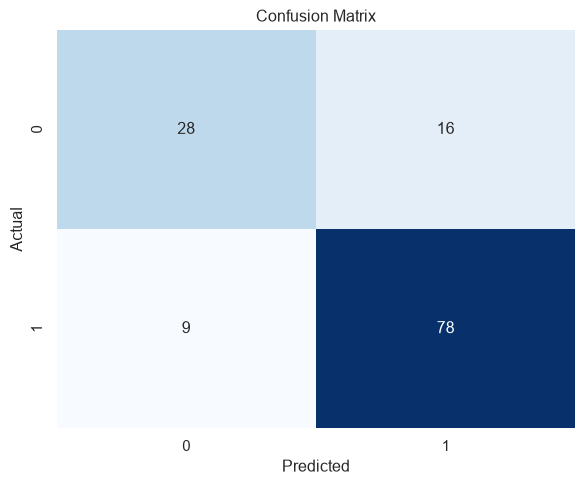

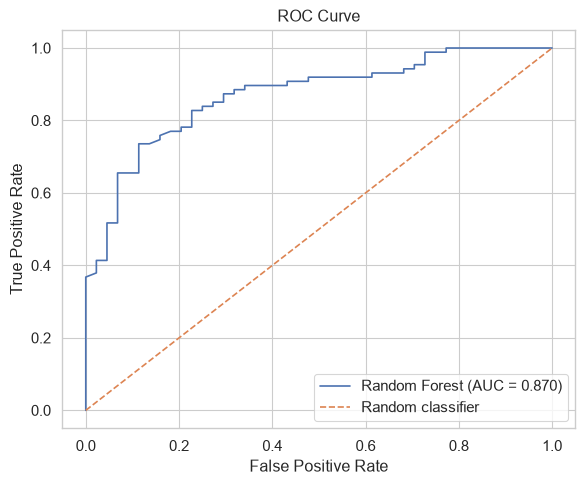

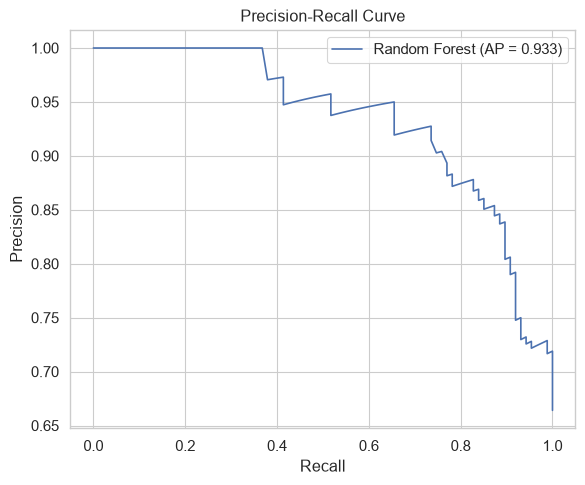

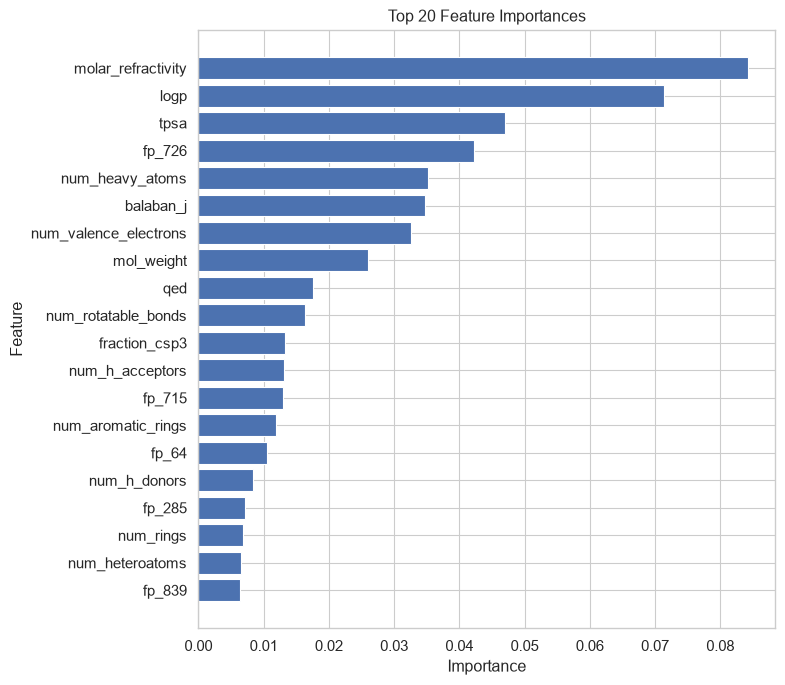

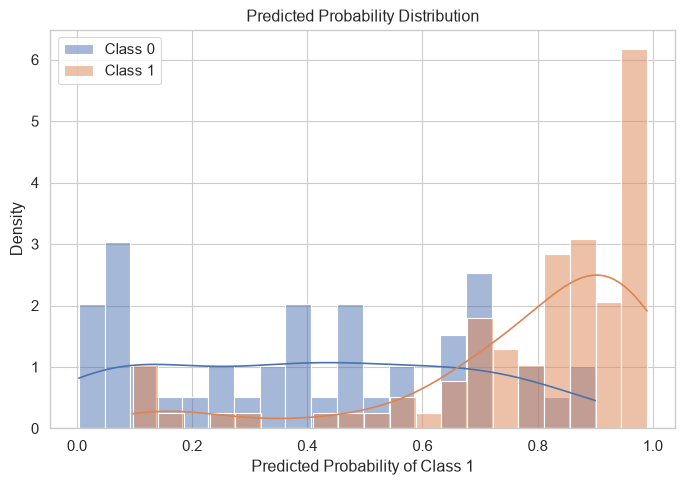

In [17]:
classification_plots(best_model, X_test, y_test, X_train.columns)